# Modèle de prédiction du retard de livraison

**Question métier (logistique)** : au moment de l'achat, la commande risque-t-elle d'arriver après la date promise au client ?

- **Cible** : `en_retard` = 1 si la commande est livrée après la date estimée.
- **Variables** : uniquement des informations connues à l'achat (distance client-vendeur, délai promis, poids et volume du colis, prix, frais de port, mois, jour, état du client, historique passé du vendeur).
- **Source** : table `mart.features_retard`, calculée par le pipeline (`sql/03_mart.sql`).

**Classes déséquilibrées** : environ 8 % de retards seulement. Un modèle qui répond toujours « pas de retard » aurait plus de 90 % d'accuracy tout en étant inutile. On suit donc surtout :
- le **rappel** (part des vrais retards détectés),
- la **précision** (part des alertes qui sont de vrais retards),
- la **F1** (compromis entre les deux),
- la **PR-AUC** (qualité du classement des commandes à risque, adaptée aux classes rares).

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    average_precision_score,
    classification_report,
    make_scorer,
    precision_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sqlalchemy import create_engine

# On se place à la racine du projet pour que le fichier .env soit trouvé
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

from shoppulse.config import settings
from shoppulse.models.delay import charger_donnees, creer_pipeline, entrainer_et_sauvegarder

engine = create_engine(settings.database_url)

## 1. Données

In [2]:
X, y = charger_donnees(engine)
print(X.shape)
print("Part des commandes en retard :", round(100 * y.mean(), 1), "%")
X.head()

(96470, 12)
Part des commandes en retard : 8.1 %


,distance_km,delai_promis_jours,nb_articles,prix_total,frais_port,poids_total_g,volume_cm3,mois_achat,jour_semaine,nb_commandes_vendeur_avant,taux_retard_vendeur_avant,customer_state
0,687.4,33.0,1,895.0,21.02,11800.0,61920.0,9.0,2.0,0,NaN,PR
1,714.3,24.0,1,895.0,21.02,11800.0,61920.0,10.0,4.0,1,0.0,MG
2,417.1,21.0,1,895.0,21.02,11800.0,61920.0,10.0,3.0,2,0.0,MG
3,1735.3,36.0,1,99.9,21.15,8875.0,24080.0,2.0,6.0,0,NaN,MT
4,523.6,30.0,5,499.5,74.35,44375.0,120400.0,2.0,6.0,1,0.0,RJ


## 2. Découpage et validation croisée

- **Jeu de test** : 20 % des commandes, mis de côté pour l'évaluation finale (découpage *stratifié* : même part de retards dans les deux jeux).
- **Validation croisée** à 5 plis stratifiés sur les 80 % restants, pour comparer les modèles sur des résultats stables.

Trois modèles :
1. **Baseline** (`DummyClassifier`) : prédit toujours la classe majoritaire (« pas de retard »). Sert de point de comparaison.
2. **Régression logistique** : modèle linéaire simple et interprétable.
3. **Random Forest** : ensemble d'arbres de décision, capable de capter des effets non linéaires (ex. : distance × délai promis).

`class_weight="balanced"` donne plus de poids aux retards pendant l'entraînement, pour que le modèle ne les ignore pas.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

modeles = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=12, class_weight="balanced", n_jobs=-1, random_state=42
    ),
}

metriques = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "rappel": "recall",
    "f1": "f1",
    "pr_auc": "average_precision",
}

plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultats = []
for nom, modele in modeles.items():
    scores = cross_validate(creer_pipeline(modele), X_train, y_train, cv=plis, scoring=metriques)
    ligne = {"modèle": nom}
    for m in metriques:
        ligne[m] = round(scores[f"test_{m}"].mean(), 3)
    resultats.append(ligne)
    print(nom, "terminé")

pd.DataFrame(resultats)

Baseline terminé
Régression logistique terminé
Random Forest terminé


,modèle,accuracy,precision,rappel,f1,pr_auc
0,Baseline,0.919,0.000,0.000,0.000,0.081
1,Régression logistique,0.664,0.145,0.645,0.237,0.187
2,Random Forest,0.821,0.239,0.550,0.333,0.288


**Lecture** :
- La **baseline** a la meilleure accuracy (91,9 %) mais ne détecte **aucun** retard (rappel 0) : c'est le piège des classes déséquilibrées.
- La **régression logistique** détecte beaucoup de retards (rappel 64,5 %), mais avec énormément de fausses alertes (précision 14,5 %).
- La **Random Forest** offre le meilleur compromis : **F1 = 0,333** et **PR-AUC = 0,288**, soit 3,5 fois mieux que le hasard (0,081). Elle est retenue comme modèle final.

## 3. Évaluation sur le jeu de test

In [4]:
logistique = creer_pipeline(modeles["Régression logistique"]).fit(X_train, y_train)
foret = creer_pipeline(modeles["Random Forest"]).fit(X_train, y_train)

predictions = foret.predict(X_test)
print("Random Forest — jeu de test")
print(classification_report(y_test, predictions, target_names=["à l'heure", "en retard"]))
print("PR-AUC :", round(average_precision_score(y_test, foret.predict_proba(X_test)[:, 1]), 3))

Random Forest — jeu de test
              precision    recall  f1-score   support

   à l'heure       0.96      0.84      0.89     17729
   en retard       0.23      0.55      0.33      1565

    accuracy                           0.82     19294
   macro avg       0.59      0.70      0.61     19294
weighted avg       0.90      0.82      0.85     19294

PR-AUC : 0.281


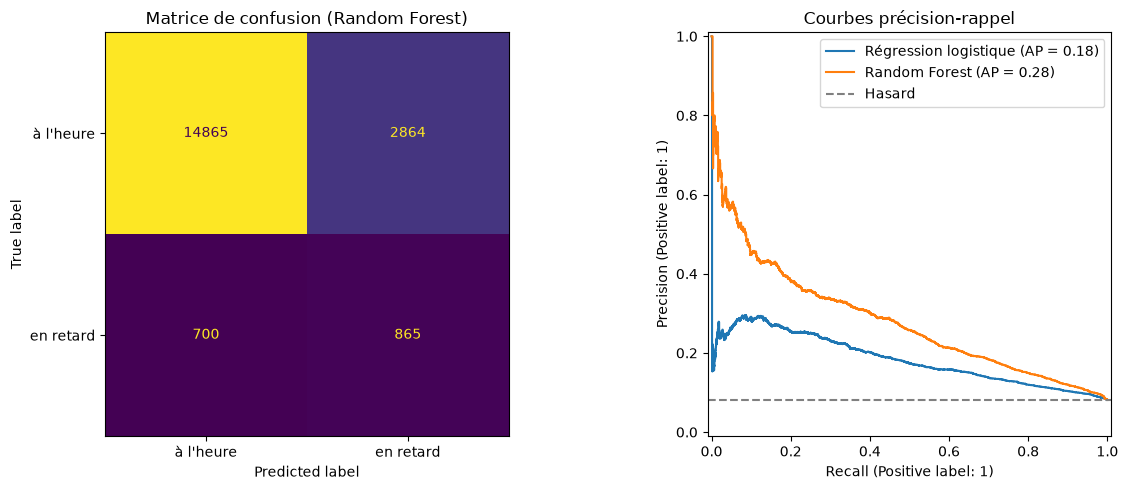

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, display_labels=["à l'heure", "en retard"], ax=axes[0], colorbar=False
)
axes[0].set_title("Matrice de confusion (Random Forest)")

PrecisionRecallDisplay.from_estimator(
    logistique, X_test, y_test, ax=axes[1], name="Régression logistique"
)
PrecisionRecallDisplay.from_estimator(foret, X_test, y_test, ax=axes[1], name="Random Forest")
axes[1].axhline(y_test.mean(), linestyle="--", color="grey", label="Hasard")
axes[1].legend()
axes[1].set_title("Courbes précision-rappel")

plt.tight_layout()
plt.show()

## 4. Variables les plus importantes

Importance calculée par la Random Forest : plus une variable est utilisée pour séparer les commandes en retard des autres, plus son importance est grande.

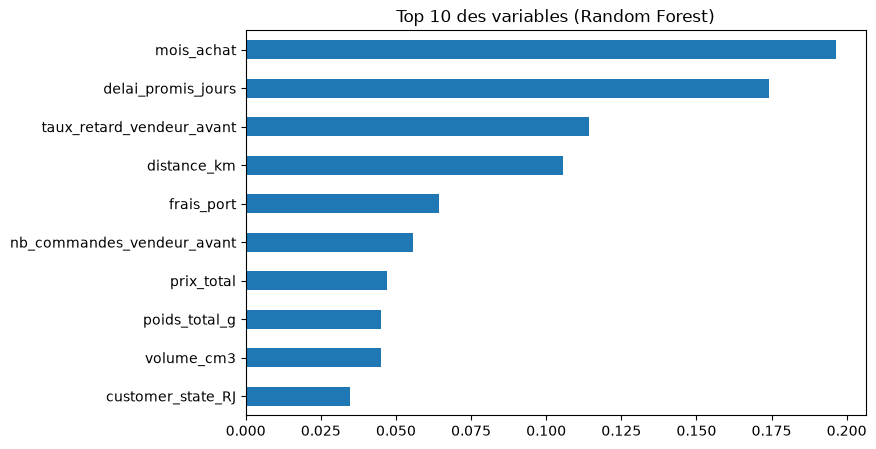

In [6]:
noms = foret.named_steps["preparation"].get_feature_names_out()
importances = pd.Series(foret.named_steps["modele"].feature_importances_, index=noms)
importances.index = importances.index.str.replace("num__", "").str.replace("cat__", "")

importances.sort_values().tail(10).plot.barh(figsize=(8, 5))
plt.title("Top 10 des variables (Random Forest)")
plt.show()

**Interprétation** :
- **Sur le jeu de test**, la Random Forest détecte **55 % des retards** (865 sur 1 565). En contrepartie, environ **1 alerte sur 4** correspond à un vrai retard (précision 23 %).
- Pour la logistique, c'est un bon usage : une alerte coûte peu (prévenir le client, prioriser l'expédition), alors qu'un retard non anticipé coûte un avis négatif (2,57/5 contre 4,29/5).
- **Variables principales** : le **mois d'achat**, le **délai promis** au client, l'**historique de retard du vendeur** et la **distance** client-vendeur. C'est cohérent avec l'EDA : les retards dépendent de la période (pics d'activité), de la promesse faite au client, du vendeur et de l'éloignement géographique.

## 5. Modèle final

Le modèle retenu est réentraîné sur **toutes** les données, puis enregistré dans `models/modele_retard.joblib`. C'est ce fichier que l'API chargera.
Le fichier n'est pas versionné (voir `.gitignore`) : il se régénère en exécutant ce notebook.

In [7]:
modele_final = entrainer_et_sauvegarder(modeles["Random Forest"], X, y)

Modèle enregistré dans models/modele_retard.joblib


## 6. Limites

- **Le mois d'achat est la variable n° 1** : le modèle a appris des périodes précises du dataset (pics comme le Black Friday 2017 ou le début 2018). Ces effets ne se reproduiront pas forcément à l'identique les années suivantes. Une **validation temporelle** (entraîner sur le passé, tester sur les mois suivants) serait plus réaliste que le découpage aléatoire utilisé ici.
- **Historique du vendeur** : il est calculé sur ses commandes passées, mais au moment d'un achat, certaines de ces commandes ne sont pas encore livrées. En production, il faudrait ne compter que les commandes déjà livrées.
- **Précision modeste** (23 %) : le seuil de décision (0,5) peut être ajusté selon le coût réel d'une fausse alerte pour la logistique.
- **Données manquantes** : 157 codes postaux clients sont absents de la géolocalisation ; leur distance est remplacée par la médiane.
- **Équité** : les taux de retard varient fortement selon les régions. L'audit d'équité vérifie que le modèle n'est pas moins performant pour certaines régions (notebook suivant).